In [2]:
import pandas as pd
import numpy as np
import json
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder, PowerTransformer
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded.")

Libraries loaded.


In [3]:
riders = pd.read_csv('riders - riders.csv.csv')
print("Riders Data:")
display(riders.head())
print("Shape:", riders.shape)

Riders Data:


,rider_id,name,age,gender,city,signup_date,total_rides,cancelled_rides,avg_rating
0,R0001,Aarav Das,23,Male,Pune,2020-06-29,56,0,3.76
1,R0002,Ishaan Nair,39,Female,Mumbai,2019-11-23,70,5,4.12
2,R0003,Kavya Reddy,34,Male,Pune,2023-05-04,45,9,3.76
3,R0004,Aarav Nair,19,Other,Kolkata,2019-07-28,464,5,3.19
4,R0005,Diya Reddy,27,Male,Ahmedabad,2021-05-31,294,30,3.53


Shape: (300, 9)


In [4]:
with open('trips.json', 'r') as f:
    trips_data = json.load(f)

trips = pd.DataFrame(trips_data)
print("Trips Data:")
display(trips.head())
print("Shape:", trips.shape)

Trips Data:


,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,payment_mode,ride_date,surge_flag
0,T00001,R0037,Zone_10,11.83,74.59,104.88,Cash,2023-11-13,0
1,T00002,R0104,Zone_9,3.86,35.59,40.48,Cash,2023-07-28,1
2,T00003,R0045,Zone_8,4.70,31.03,46.39,Cash,2024-01-14,1
3,T00004,R0089,Zone_2,11.06,59.48,257.64,Cash,2023-12-13,0
4,T00005,R0003,Zone_5,7.28,67.59,72.74,UPI,2023-03-15,1


Shape: (2000, 9)


In [5]:
conn = sqlite3.connect(':memory:')

with open('city_zones.sql', 'r') as f:
    sql_script = f.read()

conn.executescript(sql_script)

zones = pd.read_sql_query("SELECT * FROM city_zones", conn)
print("City Zones Data:")
display(zones.head())
print("Shape:", zones.shape)

City Zones Data:


,zone_name,population_density,traffic_index,avg_speed_kmph,zone_type
0,Zone_1,4921,2.43,30.9,Residential
1,Zone_2,6371,0.91,58.4,Residential
2,Zone_3,12971,2.11,38.0,Business
3,Zone_4,4038,2.46,48.2,Business
4,Zone_5,2590,1.31,43.9,Business


Shape: (10, 5)


In [6]:
print("Riders Info:")
riders.info()
print("\nMissing Values in Riders:")
print(riders.isnull().sum())

print("\nTrips Info:")
trips.info()
print("\nMissing Values in Trips:")
print(trips.isnull().sum())

print("\nZones Info:")
zones.info()
print("\nMissing Values in Zones:")
print(zones.isnull().sum())

Riders Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rider_id         300 non-null    object 
 1   name             300 non-null    object 
 2   age              300 non-null    int64  
 3   gender           300 non-null    object 
 4   city             300 non-null    object 
 5   signup_date      300 non-null    object 
 6   total_rides      300 non-null    int64  
 7   cancelled_rides  300 non-null    int64  
 8   avg_rating       300 non-null    float64
dtypes: float64(1), int64(3), object(5)
memory usage: 21.2+ KB

Missing Values in Riders:
rider_id           0
name               0
age                0
gender             0
city               0
signup_date        0
total_rides        0
cancelled_rides    0
avg_rating         0
dtype: int64

Trips Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 199

In [7]:
# Fill missing numerical values with mean
num_imputer = SimpleImputer(strategy='mean')
riders[['age', 'avg_rating']] = num_imputer.fit_transform(riders[['age', 'avg_rating']])

# Fill missing categorical values with most frequent (mode)
cat_imputer = SimpleImputer(strategy='most_frequent')
riders[['gender']] = cat_imputer.fit_transform(riders[['gender']])

# Use KNN Imputer for multivariate columns (duration, distance, fare)
knn_imputer = KNNImputer(n_neighbors=3)
trips[['distance_km', 'duration_min', 'fare_amount']] = knn_imputer.fit_transform(trips[['distance_km', 'duration_min', 'fare_amount']])

print("Missing values filled.")
print("Riders missing:", riders.isnull().sum().sum())
print("Trips missing:", trips.isnull().sum().sum())

Missing values filled.
Riders missing: 0
Trips missing: 0


In [8]:
# Cap outliers using IQR method
def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[column] = np.where(df[column] < lower, lower, df[column])
    df[column] = np.where(df[column] > upper, upper, df[column])
    return df

trips = cap_outliers(trips, 'fare_amount')
trips = cap_outliers(trips, 'distance_km')
trips = cap_outliers(trips, 'duration_min')

print("Outliers handled.")

Outliers handled.


In [9]:
riders['signup_date'] = pd.to_datetime(riders['signup_date'])
riders['signup_year'] = riders['signup_date'].dt.year
riders['signup_month'] = riders['signup_date'].dt.month
riders['signup_day'] = riders['signup_date'].dt.day
riders = riders.drop('signup_date', axis=1)

trips['ride_date'] = pd.to_datetime(trips['ride_date'])
trips['ride_hour'] = trips['ride_date'].dt.hour
trips['ride_day_of_week'] = trips['ride_date'].dt.dayofweek
trips['ride_month'] = trips['ride_date'].dt.month
trips = trips.drop('ride_date', axis=1)

print("Date features extracted.")
display(trips[['ride_hour', 'ride_day_of_week', 'ride_month']].head())

Date features extracted.


,ride_hour,ride_day_of_week,ride_month
0,0,0,11
1,0,4,7
2,0,6,1
3,0,2,12
4,0,2,3


In [10]:
le = LabelEncoder()
riders['gender'] = le.fit_transform(riders['gender'])

# One-Hot Encoding for payment_mode and zone_name
trips = pd.get_dummies(trips, columns=['payment_mode'], drop_first=True)

# Ordinal Encoding for traffic_level (Low < Medium < High)
zones['traffic_level'] = pd.cut(zones['traffic_index'], bins=3, labels=['Low', 'Medium', 'High'])
zones['traffic_level'] = le.fit_transform(zones['traffic_level'])

print("Encoding done.")
display(trips.head())

Encoding done.


,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,surge_flag,ride_hour,ride_day_of_week,ride_month,payment_mode_Credit Card,payment_mode_UPI,payment_mode_Wallet
0,T00001,R0037,Zone_10,11.83,74.59,104.88,0,0,0,11,False,False,False
1,T00002,R0104,Zone_9,3.86,35.59,40.48,1,0,4,7,False,False,False
2,T00003,R0045,Zone_8,4.70,31.03,46.39,1,0,6,1,False,False,False
3,T00004,R0089,Zone_2,11.06,59.48,257.64,0,0,2,12,False,False,False
4,T00005,R0003,Zone_5,7.28,67.59,72.74,1,0,2,3,False,True,False


In [11]:
# Binning customer ride frequency
riders['ride_frequency'] = pd.cut(riders['total_rides'], bins=3, labels=['Low', 'Medium', 'High'])
riders['ride_frequency'] = le.fit_transform(riders['ride_frequency'])

# Log transform on fare and distance
trips['fare_log'] = np.log1p(trips['fare_amount'])
trips['distance_log'] = np.log1p(trips['distance_km'])

# Square-root transform on duration
trips['duration_sqrt'] = np.sqrt(trips['duration_min'])

print("Binning and transformations applied.")
display(trips[['fare_log', 'distance_log', 'duration_sqrt']].head())

Binning and transformations applied.


,fare_log,distance_log,duration_sqrt
0,4.662306,2.551786,8.636550
1,3.725211,1.581038,5.965735
2,3.858411,1.740466,5.570458
3,5.555437,2.489894,7.712328
4,4.300545,2.113843,8.221314


In [12]:
scaler = StandardScaler()
scale_cols = ['distance_km', 'duration_min', 'fare_amount']
trips[scale_cols] = scaler.fit_transform(trips[scale_cols])

minmax = MinMaxScaler()
zones[['population_density', 'traffic_index', 'avg_speed_kmph']] = minmax.fit_transform(zones[['population_density', 'traffic_index', 'avg_speed_kmph']])

print("Scaling applied.")
display(trips[scale_cols].head())

Scaling applied.


,distance_km,duration_min,fare_amount
0,0.807880,0.359841,-0.348001
1,-0.987690,-0.734874,-1.122797
2,-0.798446,-0.862872,-1.051694
3,0.634406,-0.064291,1.489856
4,-0.217195,0.163353,-0.734677


In [13]:
merged = trips.merge(riders, on='rider_id', how='left')
merged = merged.merge(zones, left_on='zone', right_on='zone_name', how='left')

print("Merged Data Shape:", merged.shape)
display(merged.head())

Merged Data Shape: (2000, 33)


,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,surge_flag,ride_hour,ride_day_of_week,ride_month,...,signup_year,signup_month,signup_day,ride_frequency,zone_name,population_density,traffic_index,avg_speed_kmph,zone_type,traffic_level
0,T00001,R0037,Zone_10,0.807880,0.359841,-0.348001,0,0,0,11,...,2020,11,21,0,Zone_10,0.000000,0.520833,0.163636,Industrial,2
1,T00002,R0104,Zone_9,-0.987690,-0.734874,-1.122797,1,0,4,7,...,2021,5,27,2,Zone_9,0.705424,0.671875,0.916364,Mixed,0
2,T00003,R0045,Zone_8,-0.798446,-0.862872,-1.051694,1,0,6,1,...,2023,7,12,1,Zone_8,0.170345,0.723958,0.003636,Business,0
3,T00004,R0089,Zone_2,0.634406,-0.064291,1.489856,0,0,2,12,...,2022,9,21,2,Zone_2,0.322557,0.192708,1.000000,Residential,1
4,T00005,R0003,Zone_5,-0.217195,0.163353,-0.734677,1,0,2,3,...,2023,5,4,1,Zone_5,0.012308,0.401042,0.472727,Business,2


In [14]:
# Create new features
merged['avg_ride_distance'] = merged['distance_km'] / (merged['total_rides'] + 1)
merged['avg_ride_fare'] = merged['fare_amount'] / (merged['total_rides'] + 1)

# Peak hour flag (7-9 AM and 18-21 PM)
merged['is_peak_hour'] = merged['ride_hour'].apply(lambda x: 1 if (7 <= x <= 9) or (18 <= x <= 21) else 0)

# Days since signup
merged['days_since_signup'] = (pd.Timestamp.now() - pd.to_datetime(merged['signup_year'].astype(str) + '-' + merged['signup_month'].astype(str) + '-' + merged['signup_day'].astype(str))).dt.days

# Cancellation rate
merged['ride_cancellation_rate'] = merged['cancelled_rides'] / (merged['total_rides'] + 1)

# Surge flag based on fare/distance threshold
merged['surge_flag'] = np.where((merged['fare_amount'] / (merged['distance_km'] + 1)) > 20, 1, 0)

print("New features created.")
display(merged[['avg_ride_distance', 'avg_ride_fare', 'is_peak_hour', 'days_since_signup', 'ride_cancellation_rate', 'surge_flag']].head())

New features created.


,avg_ride_distance,avg_ride_fare,is_peak_hour,days_since_signup,ride_cancellation_rate,surge_flag
0,0.001649,-0.000710,0,2138,0.012245,0
1,-0.003002,-0.003413,0,1951,0.003040,0
2,-0.007905,-0.010413,0,1175,0.158416,0
3,0.002053,0.004822,0,1469,0.019417,0
4,-0.004722,-0.015971,0,1244,0.195652,0


Final Dataset Shape: (2000, 38)

Final Columns:
['trip_id', 'rider_id', 'zone', 'distance_km', 'duration_min', 'fare_amount', 'surge_flag', 'ride_hour', 'ride_day_of_week', 'ride_month', 'payment_mode_Credit Card', 'payment_mode_UPI', 'payment_mode_Wallet', 'fare_log', 'distance_log', 'duration_sqrt', 'name', 'age', 'gender', 'city', 'total_rides', 'cancelled_rides', 'avg_rating', 'signup_year', 'signup_month', 'signup_day', 'ride_frequency', 'zone_name', 'population_density', 'traffic_index', 'avg_speed_kmph', 'zone_type', 'traffic_level', 'avg_ride_distance', 'avg_ride_fare', 'is_peak_hour', 'days_since_signup', 'ride_cancellation_rate']


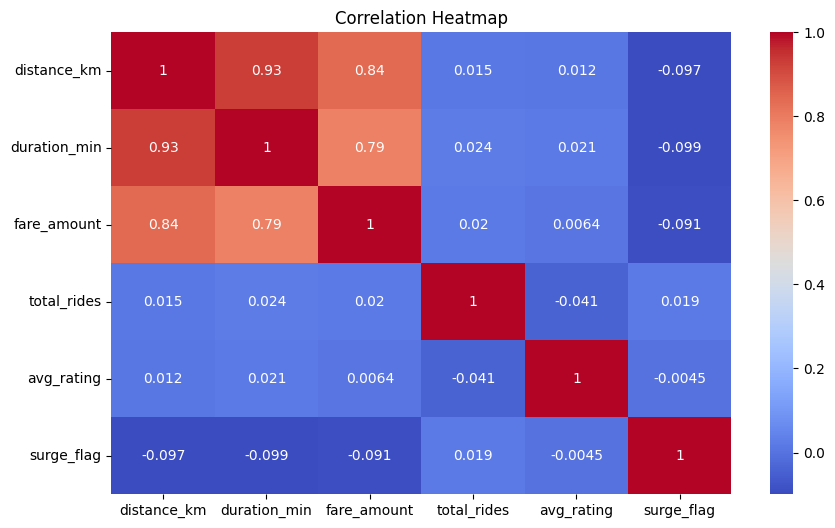

File saved as final_prepared_rides_dataset.csv


In [15]:
print("Final Dataset Shape:", merged.shape)
print("\nFinal Columns:")
print(merged.columns.tolist())

plt.figure(figsize=(10, 6))
sns.heatmap(merged[['distance_km', 'duration_min', 'fare_amount', 'total_rides', 'avg_rating', 'surge_flag']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

merged.to_csv('final_prepared_rides_dataset.csv', index=False)
print("File saved as final_prepared_rides_dataset.csv")